In [ ]:
# Stock prediction
# The use of this code is at your own risk. The instructor is not liable for any consequences arising from its use.
import numpy as np
import matplotlib.pyplot as plt
from pandas import read_csv
from keras.models import Sequential
from keras.layers import Input, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
import tensorflow as tf

from keras.layers import LSTM

In [ ]:
# Do not modify this cell.
# This is to use the fixed initial parameters in the DL model.
tf.keras.utils.set_random_seed(42)

In [ ]:
# Do not modify this cell.
# Load the dataset, convert pandas dataframe to numpy array
dataframe = read_csv('CHEMATE114_08_AAPL_stock.csv').iloc[:,[1,3,4,5]]
dataset = dataframe.values # As we handle multi-dimensional data, convert the DataFrame to a NumPy array using dataframe.values.

In [ ]:
# Do not modify this cell.
# Show the pandas dataframe.
dataframe.head()

,Close/Last,Open,High,Low
0,223.83,219.79,224.12,219.79
1,223.66,224.74,227.03,222.30
2,222.78,224.78,225.63,221.41
3,229.86,224.02,232.15,223.98
4,238.26,230.85,240.19,230.81


In [ ]:
# Do not modify this cell.
# Show the numpy dataset.
dataset[0:5]

array([[223.83, 219.79, 224.12, 219.79],
       [223.66, 224.74, 227.03, 222.3 ],
       [222.78, 224.78, 225.63, 221.41],
       [229.86, 224.02, 232.15, 223.98],
       [238.26, 230.85, 240.19, 230.81]])

In [ ]:
# Do not modify this cell.
# Split into train and test sets
# Used the past 10% of the data for testing and the preceding 90% for training. Used NumPy slicing to achieve this.
train_size = int(len(dataset) * 0.9)
test_size = len(dataset) - train_size
train, test = dataset[0:train_size,:], dataset[train_size:,:]

In [ ]:
# Modify this cell.
# Define a function to create a dataset matrix. 1 is specified as a default value for timesteps.
# timesteps: number of past days used as input.

def create_dataset(dataset, timesteps=1):
	dataX, dataY = [], []
	for i in range(len(dataset)-timesteps):
		dataX.append(dataset[i:(i+timesteps), :]) #change to : to include all 4 features (previously, it was just the 0 column)
		dataY.append(dataset[i+timesteps, 0])
	return np.array(dataX), np.array(dataY)

In [ ]:
# Do not modify this cell.
# Create the dataset
timesteps = 7
trainX, trainY = create_dataset(train, timesteps)
testX, testY = create_dataset(test, timesteps)

In [ ]:
# Do not modify this cell.
# Normalize the dataset and reshape it back to the original shape.
scaler = MinMaxScaler()
trainX_reshaped = trainX.reshape(-1, trainX.shape[2])
trainX_normalized = scaler.fit_transform(trainX_reshaped).reshape(trainX.shape)
testX_reshaped = testX.reshape(-1, testX.shape[2])
testX_normalized = scaler.transform(testX_reshaped).reshape(testX.shape)
# Reshape output to be [samples, features] (Just in case)
trainY = trainY.reshape(-1, 1)
testY = testY.reshape(-1, 1)

In [ ]:
# Modify this cell.
# Create the model.
model = Sequential()
model.add(Input(shape=(timesteps, 4))) #updated to 4 for 4 features (previously just 1)
model.add(LSTM(100, return_sequences=True))
model.add(LSTM(100))
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam')

In [ ]:
# Do not modify this cell.
# Fit the model.
model.fit(trainX_normalized, trainY, epochs=100, batch_size=1, verbose=2)

Epoch 1/100
219/219 - 5s - 22ms/step - loss: 43629.9414
Epoch 2/100
219/219 - 2s - 9ms/step - loss: 34453.7930
Epoch 3/100
219/219 - 2s - 9ms/step - loss: 27417.1914
Epoch 4/100
219/219 - 4s - 17ms/step - loss: 21582.8789
Epoch 5/100
219/219 - 2s - 10ms/step - loss: 16771.0234
Epoch 6/100
219/219 - 2s - 10ms/step - loss: 12846.0068
Epoch 7/100
219/219 - 2s - 9ms/step - loss: 9690.4404
Epoch 8/100
219/219 - 2s - 9ms/step - loss: 7197.9702
Epoch 9/100
219/219 - 2s - 10ms/step - loss: 5270.3706
Epoch 10/100
219/219 - 3s - 15ms/step - loss: 3816.3223
Epoch 11/100
219/219 - 2s - 9ms/step - loss: 2751.0791
Epoch 12/100
219/219 - 2s - 10ms/step - loss: 1996.8057
Epoch 13/100
219/219 - 2s - 10ms/step - loss: 1483.3517
Epoch 14/100
219/219 - 2s - 10ms/step - loss: 1149.2660
Epoch 15/100
219/219 - 3s - 12ms/step - loss: 942.7531
Epoch 16/100
219/219 - 3s - 12ms/step - loss: 822.2404
Epoch 17/100
219/219 - 5s - 22ms/step - loss: 756.2687
Epoch 18/100
219/219 - 2s - 10ms/step - loss: 722.6077
Epoc

In [ ]:
# Do not modify this cell.
# Make predictions
trainPredict = model.predict(trainX_normalized) # This is for the plot.
testPredict = model.predict(testX_normalized)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


In [ ]:
# Do not modify this cell.
# Calculate mean absolute error
trainScore = mean_absolute_error(trainY, trainPredict)
print(f'Train Score: MAE {trainScore}')
testScore = mean_absolute_error(testY, testPredict)
print(f'Test Score: MAE {testScore}')

Train Score: MAE 3.6028168142658403
Test Score: MAE 6.296505351819493


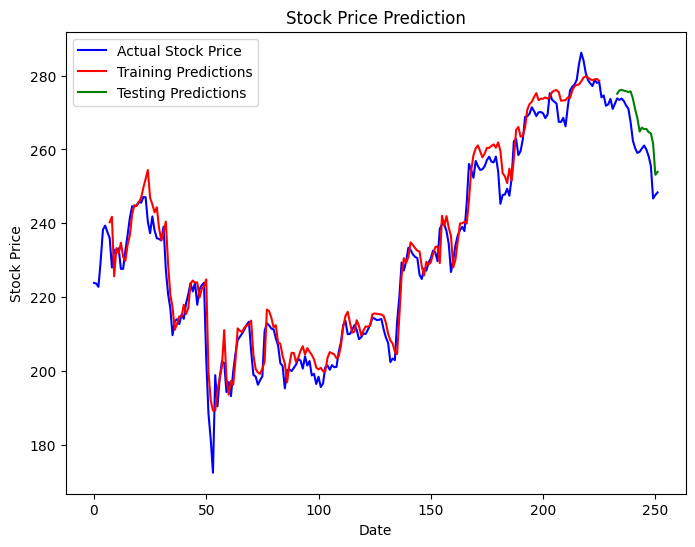

In [ ]:
# Do not modify this cell.
# The following code is to plot the results.
# Plot the results
train_dates = dataframe.index[timesteps:train_size]
test_dates = dataframe.index[train_size+timesteps:]
plt.figure(figsize=(8, 6))
plt.plot(dataframe.index, dataset[:,0].flatten(), label='Actual Stock Price', color='blue')
plt.plot(train_dates, trainPredict.flatten(), label='Training Predictions', color='red')
plt.plot(test_dates, testPredict.flatten(), label='Testing Predictions', color='green')
plt.title('Stock Price Prediction')
plt.xlabel('Date')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

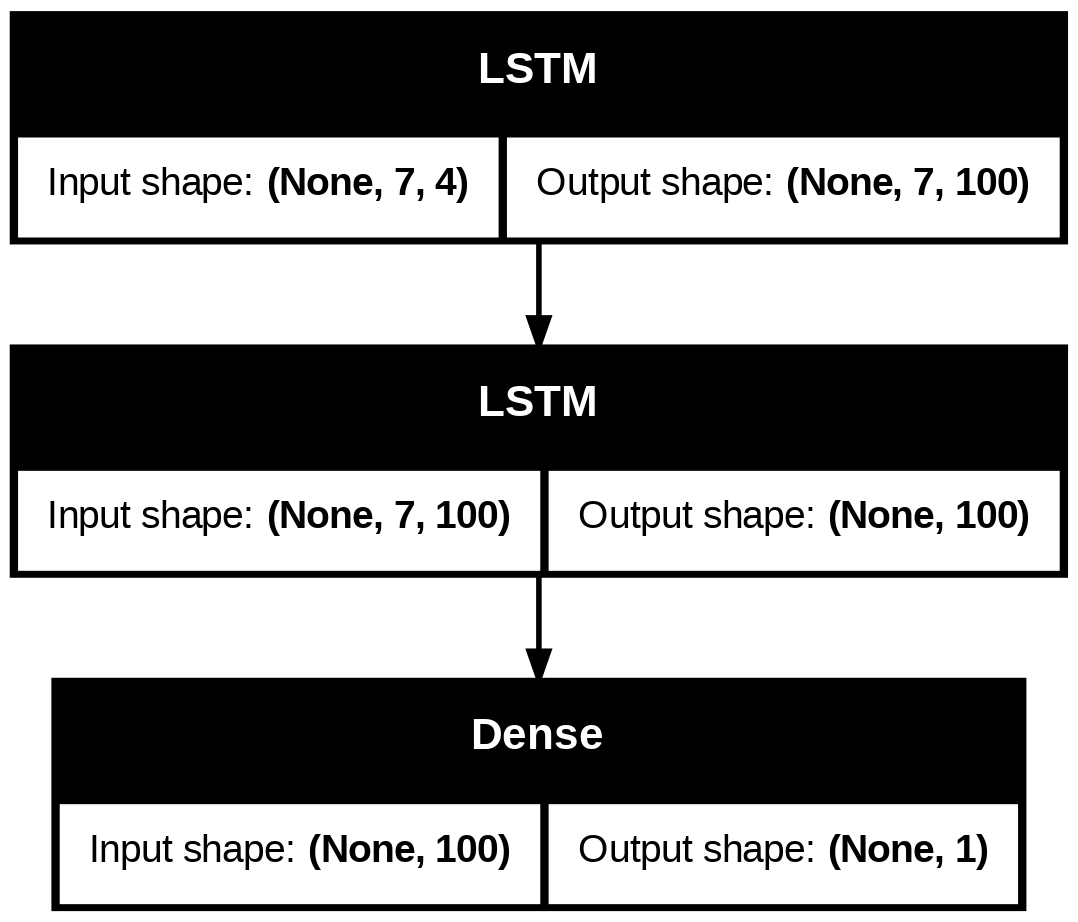

In [ ]:
tf.keras.utils.plot_model(model, show_shapes=True)